## A2 · Conditions and loops

Comparisons, if/elif/else, for loops and the counter and accumulate patterns used in the population models.

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

### Comparisons and booleans

#### Comparing values

**A2.01**

`> < == != >= <=`

Comparison operators allow us to test how two values relate, giving `True` or `False`. They are useful for conditions in `if` statements and for filtering data. Alternatively, in pandas the same operators build whole masks of True/False values.

Comparisons return `True` or `False`. Note `==` (is equal to) versus `=` (assign a value).

In [82]:
x = 7
print(x > 5)
print(x < 5)
print(x == 7)     # equal to
print(x != 7)     # not equal to
print(x >= 7)
print(x <= 6)

True
False
True
False
True
False


Text can also be compared. The comparison is case sensitive:

In [83]:
'cod' == 'cod'

True

In [84]:
'cod' == 'Cod'   # capital letters matter

False

*See also:* Combining conditions with `and`, `or`, `not` (A2) · Building a mask (B3) · Combining conditions with `&` and `|` (B3)

#### Combining conditions with `and`, `or`, `not`

**A2.02**

`and, or, not`

The words `and`, `or` and `not` allow us to combine several tests into one. They are useful when a decision depends on more than one thing. Alternatively, in pandas use `&`, `|` and `~` instead.

`and` needs both parts to be true; `or` needs at least one; `not` flips the answer.

In [85]:
ph = 7.2
ph                              # the value tested

7.2

In [86]:
print(ph > 6.5 and ph < 8.5)    # both true
print(ph < 6.5 or ph > 8.5)     # neither true
print(not ph > 6.5)             # flips True to False
print(6.5 <= ph <= 8.5)         # Python also allows a chained comparison

True
False
False
True


*See also:* Comparing values (A2) · Combining conditions with `&` and `|` (B3)

#### Testing membership with `in`

**A2.03**

`x in mylist, x not in mylist`

The `in` operator allows us to ask whether a value is present in a list, text or dictionary. It is useful for checking before a value is looked up. Alternatively, `list.count(x) > 0` does the same, but `in` is clearer.

`in` checks whether a value is in a list (or a key is in a dictionary, or a word is in text).

In [87]:
mylist = [165, 187, 333]
333 in mylist

True

In [88]:
100 not in mylist

True

In [89]:
'cod' in 'codfish'   # works for text too

True

*See also:* Creating a list (A3) · Testing whether a key exists (A3) · Filtering with `~`, `isin()` and `between()` (B3)

### if / elif / else

#### Choosing with `if` and `else`

**A2.04**

`if cond: ... else: ...`

An `if … else` statement allows us to run different code depending on a condition. It is useful for decisions that depend on the data. Alternatively, `np.where()` makes the same choice for every value in a column at once.

The indented lines run only when the condition is `True`. The indentation matters.

In [90]:
reading = 120
if reading > 100:
    print("high")
else:
    print("normal")
print("this line always runs")   # not indented, so not part of the if

high
this line always runs


Changing `reading` to 70 selects the other branch.

*See also:* Adding a conditional column with `np.where` (B4) · Choosing between several cases with `elif` (A2) · Comparing values (A2)

#### Choosing between several cases with `elif`

**A2.05**

`if ... elif ... else`

Adding `elif` allows us to test several conditions in order and run only the first that is true. It is useful for more than two outcomes. Alternatively, `pd.cut()` sorts a whole column into categories.

Conditions are checked from the top and only the **first** one that is `True` runs, so put the most specific test first.

In [91]:
for reading in [45, 80, 130]:
    if reading > 100:
        print(f"{reading} high")
    elif reading > 60:
        print(f"{reading} normal")
    else:
        print(f"{reading} low")

45 low
80 normal
130 high


*See also:* Binning numbers into categories (B4) · Choosing with `if` and `else` (A2) · Combining conditions with `and`, `or`, `not` (A2) · IndentationError: unexpected indent (A1)

### for loops

#### Repeating n times with `range(n)`

**A2.06**

`for i in range(n):`

The `for i in range(n)` loop allows us to repeat code `n` times. It is useful when the number of repeats is known in advance. Alternatively, loop directly over a list, or use a NumPy array operation to avoid the loop.

`range(5)` gives 0, 1, 2, 3, 4: it starts at 0 and stops *before* 5. The indented code runs once for each value.

In [92]:
for i in range(5):
    print(i)

0
1
2
3
4


`list(range(5))` shows the values as a list:

In [93]:
list(range(5))

[0, 1, 2, 3, 4]

*See also:* Counting from a to b with `range(a, b)` (A2) · Counting with a counter (A2) · Looping over a list (A2)

#### Counting from a to b with `range(a, b)`

**A2.07**

`range(a, b)`

Giving `range` two numbers allows us to start somewhere other than zero. It is useful for years, IDs or any sequence with a chosen first value. Alternatively, `np.arange(a, b)` does the same and also handles decimals.

Two numbers choose where to start and stop. The end value is excluded.

In [94]:
for i in range(2, 5):
    print(i)
list(range(1, 11))   # 1 to 10

2
3
4


[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

*See also:* Creating a sequence with `np.arange` (A4) · Repeating n times with `range(n)` (A2) · Counting in steps with `range(a, b, step)` (A2)

#### Looping over a list

**A2.08**

`for item in mylist:`

A `for` loop over a list allows us to do something with each item in turn. It is useful when a collection is held and every element must be processed. Alternatively, a list comprehension builds a new list in one line.

Loop directly over the items of a list: no index is needed.

In [95]:
fish = ["cod", "eel", "bream"]
for f in fish:
    print(f.upper(), len(f))

COD 3
EEL 3
BREAM 5


*See also:* Creating a list (A3) · Numbering items with `enumerate` (A2) · Looping over two lists with `zip` (A2)

#### Counting in steps with `range(a, b, step)`

**A2.09**

`range(a, b, step)`

***(non-examinable)***

A third argument to `range` allows us to skip values or count backwards. It is useful for every-other-item sequences. Alternatively, `np.arange(start, stop, step)` allows decimal steps.

In [96]:
list(range(0, 10, 2))     # 0, 2, 4, 6, 8

[0, 2, 4, 6, 8]

In [97]:
list(range(10, 0, -3))    # counting down

[10, 7, 4, 1]

*See also:* Counting from a to b with `range(a, b)` (A2) · Creating a sequence with `np.arange` (A4) · Repeating n times with `range(n)` (A2)

### Loop patterns

#### Counting with a counter

**A2.10**

`counter = counter + 2`

The counter pattern allows us to count or total things as a loop runs. It is useful whenever a loop must count or total what it sees. Alternatively, pandas does this in one step with `(df['col'] == 6).sum()`.

Start a variable *before* the loop, update it inside, and use it *after*.

In [98]:
counter = 0
for i in range(5):
    counter = counter + 2
counter

10

Counting how many items meet a condition:

In [99]:
rolls = [3, 6, 2, 6, 5, 6]
sixes = 0
for r in rolls:
    if r == 6:
        sixes = sixes + 1
print(f"sixes: {sixes}")

sixes: 3


*See also:* Updating a value on each pass (A2) · Updating a variable with `+=` and `abs()` (A1) · Repeating until a condition fails with `while` (A2)

#### Updating a value on each pass

**A2.11**

`n = n + n * rate`

The update pattern allows us to change a variable each time round a loop, using its previous value. It is useful when each step depends on the one before. Alternatively, a formula such as `n0 * (1 + rate) ** t` gives the answer directly.

Each year the population grows by a fixed fraction of its current size.

In [100]:
n = 1000        # starting population
rate = 0.05     # 5% growth per year
for year in range(3):
    n = n + n * rate
    print(f"after year {year + 1} : {round(n, 1)}")

after year 1 : 1050.0
after year 2 : 1102.5
after year 3 : 1157.6


*See also:* Counting with a counter (A2) · Collecting results in a list with `append` (A2) · Repeating until a condition fails with `while` (A2)

#### Collecting results in a list with `append`

**A2.12**

`year.append(i)`

Starting with an empty list and calling `.append()` in a loop allows us to collect results as we go. It is useful when the result of every step must be kept. Alternatively, a list comprehension or a NumPy array can build the results without an explicit loop.

Start with empty lists, add to them inside the loop, then use them afterwards: this is how results are collected for plotting.

In [101]:
years = []
pop = []
n = 1000
for i in range(6):
    years.append(i)
    pop.append(n)
    n = n + n * 0.1

years

[0, 1, 2, 3, 4, 5]

In [102]:
[round(p) for p in pop]

[1000, 1100, 1210, 1331, 1464, 1611]

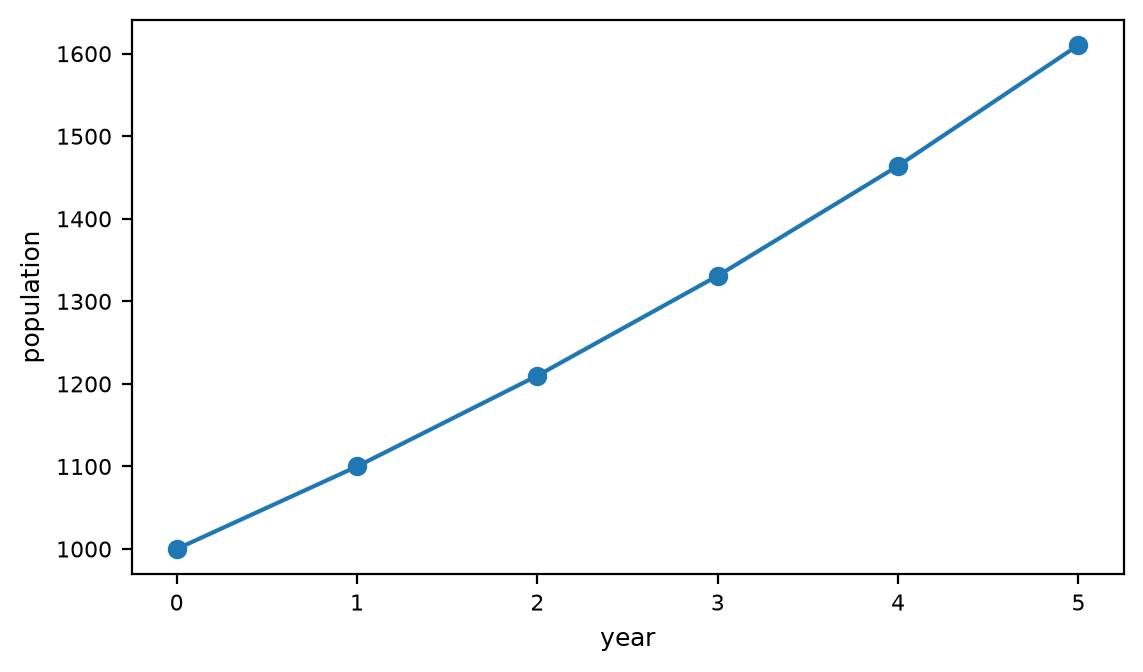

In [103]:
plt.plot(years, pop, "o-")
plt.xlabel("year")
plt.ylabel("population");

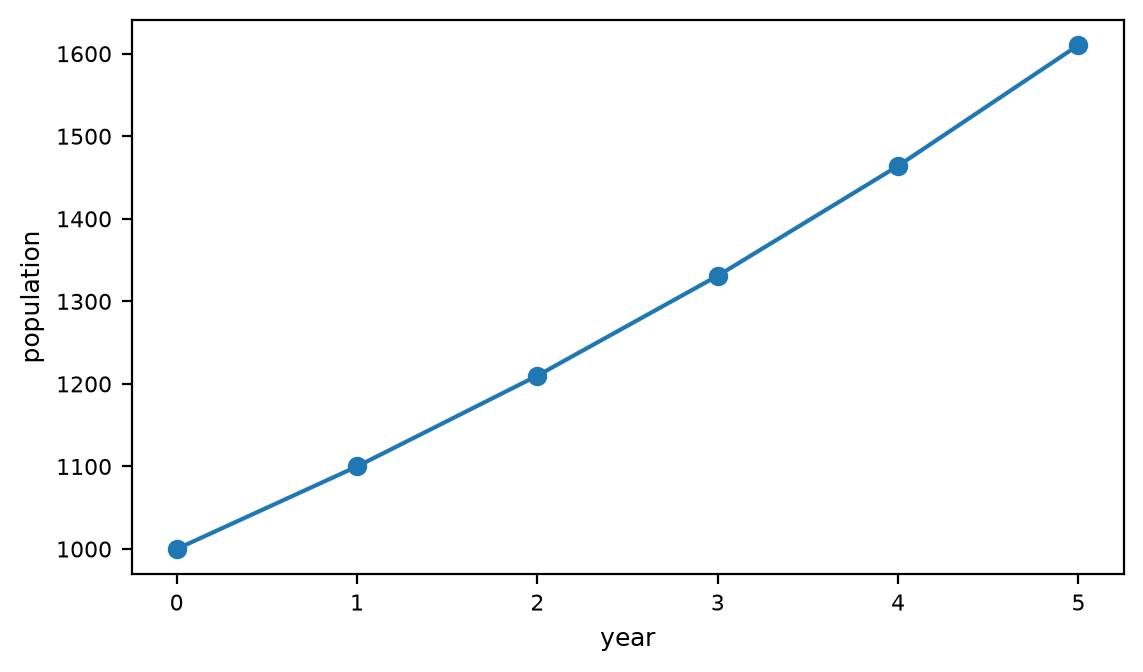

In [104]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(years, pop, "o-")
ax.set_xlabel("year")
ax.set_ylabel("population");

*See also:* Updating a value on each pass (A2) · Adding an item to a list (A3) · Drawing a simple line plot (C1)

### More loops and functions

#### Repeating until a condition fails with `while`

**A2.13**

`while cond:`

***(non-examinable)***

A `while` loop allows us to repeat code until a condition stops being true. It is useful when the number of repeats is not known in advance. Alternatively, a `for` loop with `range` suits a known number of repeats.

Repeats until the condition becomes `False`. Something inside the loop must change it, or the loop never ends.

In [105]:
n = 100
years = 0
while n < 200:
    n = n * 1.1
    years += 1
print(f"{years} years to double, final size {round(n, 1)}")

8 years to double, final size 214.4


*See also:* Updating a value on each pass (A2) · Numbering items with `enumerate` (A2)

#### Numbering items with `enumerate`

**A2.14**

`for i, x in enumerate(lst):`

***(non-examinable)***

The `enumerate` function allows us to get each item together with its position. It is useful for numbering items during a loop. Alternatively, `range(len(lst))` gives the positions, and the items are then read by index.

The position and the item are obtained together.

In [106]:
for i, f in enumerate(["cod", "eel", "bream"]):
    print(i, f)

0 cod
1 eel
2 bream


*See also:* Repeating n times with `range(n)` (A2) · Looping over a list (A2) · Looping over two lists with `zip` (A2)

#### Looping over two lists with `zip`

**A2.15**

`for a, b in zip(l1, l2):`

***(non-examinable)***

The `zip` function allows us to loop over two (or more) lists in step with each other. It is useful when the lists are matched up.

Two lists are looped over in step with each other.

In [107]:
names = ["cod", "eel"]
masses_kg = [12.5, 3.1]
for name, mass in zip(names, masses_kg):
    print(f"{name} has a mass of {mass} kg")

cod has a mass of 12.5 kg
eel has a mass of 3.1 kg


*See also:* Numbering items with `enumerate` (A2) · Looping over a list (A2) · Creating a DataFrame from a dictionary (B1)

#### Writing a function with `def`

**A2.16**

`def f(x): return ...`

***(non-examinable)***

The `def` statement allows us to package code under a name so we can reuse it. It is useful when the same calculation is repeated with different inputs. Alternatively, a `lambda` makes a short one-line function.

A function packages code that is to be reused. `return` sends the answer back.

In [108]:
def to_celsius(f):
    return (f - 32) * 5 / 9

to_celsius(212)   # boiling point of water

100.0

In [109]:
to_celsius(77)

25.0

*See also:* Applying a function (B9) · Repeating until a condition fails with `while` (A2) · Checking data with `assert` (B1)